# 06-04 - A Vector for Every Place

You read the 64 numbers a planetary model wrote for every cell of the town, and search, cluster and map with them.

We start with the toy. Then the town: two years of vectors, three places' numbers, the town as three colours, a search from a click, clusters named by the labels, a map from 25 labelled cells per class scored against the forest, the lecture's curve, the change since 2018. At the end you change how many labels the map gets.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import fm_tools as fm

plt.rcParams["figure.dpi"] = 72

scene = fm.load_scene("data/scene.json")
reference = json.load(open("data/ground_truth.json"))["p06"]
torch_ok = fm.torch_available()
ready = {name: torch_ok and fm.model_ready(name) for name in ("sam2", "clip")}
print(f"the window of {scene['window']['date']}: {scene['window']['pixels']:,} pixels a side at "
      f"{scene['window']['resolution_m']} m, {scene['blocks']['n']} blocks, "
      f"{scene['chips']['tiled']['total']:,} chips; the deep learning library is "
      f"{'ready' if torch_ok else 'missing, so the cells that need it are skipped'}; the open models are "
      f"{'ready' if all(ready.values()) else 'not loadable here, so the cells that run them are skipped'}")

the window of 2023-08-20: 10,240 pixels a side at 0.3 m, 25 blocks, 1,600 chips; the deep learning library is ready; the open models are ready


## Seven places, three numbers each

The cell reads the toy of the lecture, seven unit vectors of three numbers for roofs, lawns, ponds and a car park, and finds the car park's nearest neighbour.

car park [0.8, 0.0, 0.6]: cosines with the six known places roof 1 0.80, roof 2 0.93, lawn 1 0.00, lawn 2 0.58, pond 1 0.60, pond 2 0.86
its nearest neighbour is roof 2 at 0.93   reference roof 2 at 0.928; the nearest centroid says roof


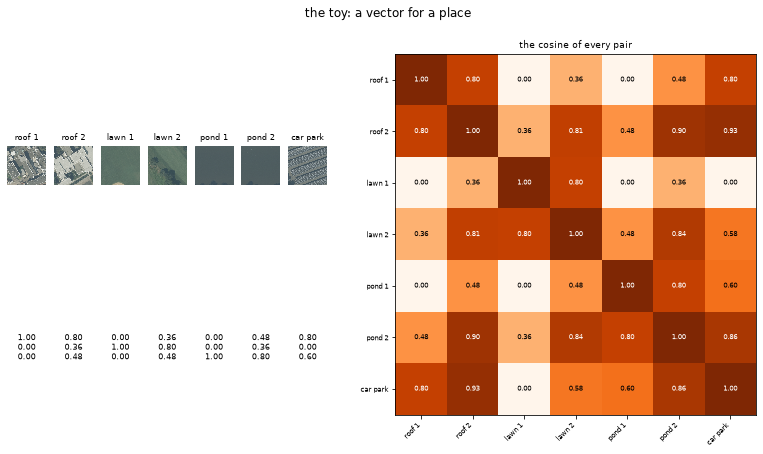

In [2]:
toy = json.load(open("data/toy.json"))
pics = fm.read_npz("data/toy_places.npz")
names, V = toy["names"], np.asarray(toy["vectors"])
cos = V @ V.T
nearest, rt = names[int(np.argmax(cos[-1, :-1]))], reference["toy"]
print(f"{names[-1]} {V[-1].tolist()}: cosines with the six known places "
      + ", ".join(f"{n} {v:.2f}" for n, v in zip(names[:-1], cos[-1, :-1])))
print(f"its nearest neighbour is {nearest} at {cos[-1, :-1].max():.2f}   reference {rt['nearest']} at "
      f"{rt['nearest_sim']}; the nearest centroid says {rt['centroid_rule']}")
pictures = [pics[n.replace(" ", "_")] for n in names]
fig = fm.show_toy(names, V.tolist(), cos, pictures, "the toy: a vector for a place")

A vector for a place is a list of numbers, and the cosine between two lists is the similarity the day runs on: 1 for the same direction, 0 for unrelated, the dot product when the lists have unit length. The toy's three numbers were chosen so that every cosine has two decimals; the model's 64 numbers were not chosen by anyone and mean nothing one by one. The car park is nearest to a roof, as the lecture's nearest-neighbour rule and its nearest centroid said.

## The town as 64 numbers per cell

The cell reads the town's vectors of 2021 and 2025 from their bytes, checks that they have unit length, and draws the 64 numbers of three places.

64 numbers for each of 476,595 cells of 10 m inside the town; median length 1.0001   reference 1.0001
The AlphaEarth Foundations Satellite Embedding dataset is produced by Google and Google DeepMind
cosines: Hall and lawn 0.36, Hall and lake 0.34, lawn and lake 0.30, Hall and the lot 0.64   reference [0.3622, 0.3433, 0.2975, 0.6381]


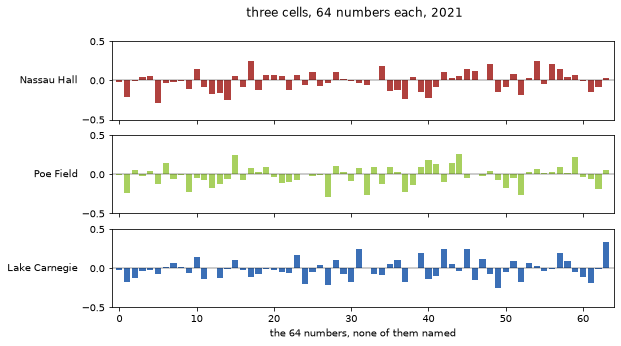

In [3]:
e21, e25 = fm.read_embeddings("data/aef_town_2021.tif"), fm.read_embeddings("data/aef_town_2025.tif")
q, valid, tr = e21["q"], e21["valid"], e21["transform"]
lengths = np.sqrt((q[:, valid] ** 2).sum(axis=0))
print(f"{q.shape[0]} numbers for each of {int(valid.sum()):,} cells of {e21['res']:.0f} m inside the town; "
      f"median length {np.median(lengths):.4f}   reference {reference['embeddings']['unit_length_median']}")
print(e21["tags"]["attribution"])
vec = {k: q[:, p["row"], p["col"]] for k, p in scene["places"].items()}
nh, pf, lc, lot = (vec[k] for k in ("nassau_hall", "campus_lawn", "lake_carnegie", "parking_lot"))
print(f"cosines: Hall and lawn {nh @ pf:.2f}, Hall and lake {nh @ lc:.2f}, lawn and lake {pf @ lc:.2f}, "
      f"Hall and the lot {nh @ lot:.2f}   reference {list(reference['embeddings']['pairs_2021'].values())}")
fig = fm.show_vectors([nh, pf, lc], ["Nassau Hall", "Poe Field", "Lake Carnegie"],
                      ["#b0413e", "#a8d05f", "#3b6fb6"], "three cells, 64 numbers each, 2021")

The file holds a byte per number, and the byte becomes a number by the rule in the tags, a square that keeps the sign, after which every cell's 64 numbers have length one. That is the whole format: 64 bands on the Sentinel-2 grid of Lecture 04, one file per year, with the attribution line the licence requires in the tags. The bar strips show that no number can be read on its own; the cosine can, and the Hall is nearer the parking lot than the lawn.

## Three principal components as colour

The cell fits a principal component analysis on a sample of the cells, draws the first three components as colours, and reads the labels and cells of Lecture 04.

three components explain 32.5%, 16.8% and 10.3% of the variance   reference 32.5%, 16.8%, 10.3%


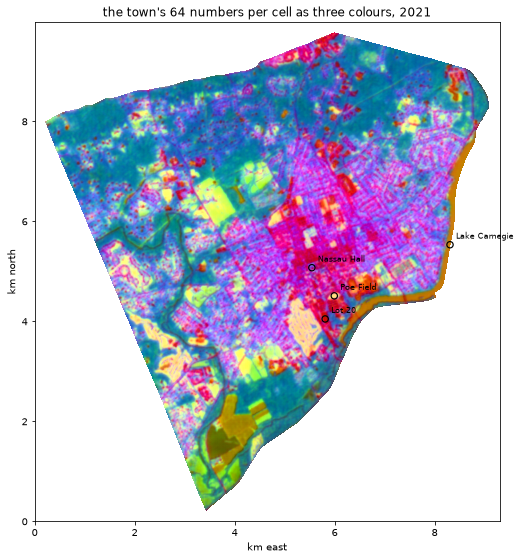

In [4]:
rgb, components, explained = fm.pca_rgb(q, valid)
extent = fm.extent_of(tr, q.shape[1:])
marks = {p["name"]: (p["x"], p["y"]) for p in scene["places"].values()}
labels10, _, _, _ = fm.read_raster("data/labels_2021.tif")
cells = fm.read_npz("data/cells.npz")
ho, y_ho = fm.held_out_cells(valid, labels10, cells["held_out"])
print(f"three components explain {explained[0]:.1%}, {explained[1]:.1%} and {explained[2]:.1%} of the "
      f"variance   reference " + ", ".join(f"{v:.1%}" for v in reference["embeddings"]["pca"]["2021"]))
fig, ax = plt.subplots(figsize=(9, 9))
fm.show_map(ax, rgb, extent, "the town's 64 numbers per cell as three colours, 2021", places=marks)

Sixty-four numbers cannot be drawn, three can. The analysis finds the three directions along which the town's vectors vary most, and the colour of a cell is where it falls along them, stretched between the second and the 98th percentile. The three directions carry six tenths of the variance. Water, woods, lawns and streets fall into their own colours without a label having been read, and the campus and the downtown share one. The colours are arbitrary; that like places share them is the finding.

## Similarity search from a click

The cell takes one cell's 2025 vector, computes its cosine with every cell of the town, counts the cells above a threshold and circles the ten most similar.

Nassau Hall: 60,958 cells above 0.85; the ten most similar a kilometre apart, from 0.96, 0.95, 0.94 down   reference 60,958, 0.9594
Lot 20: 1,862 cells above 0.85; the ten most similar a kilometre apart, from 0.94, 0.94, 0.92 down   reference 1,862, 0.9353


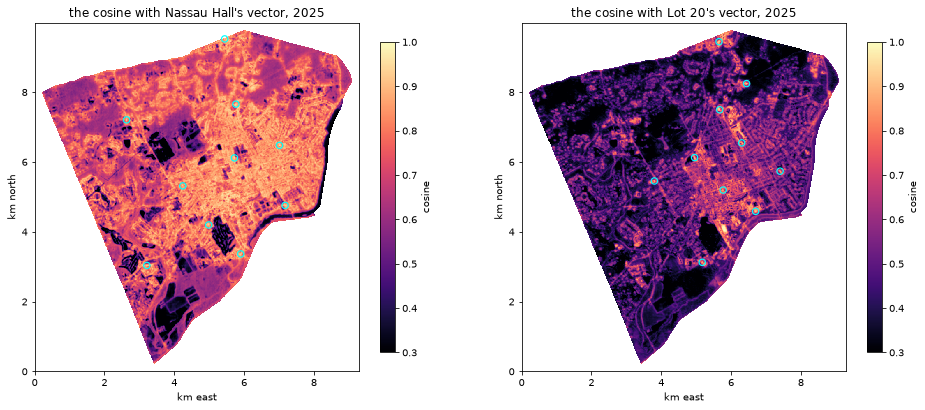

In [5]:
q25, t = e25["q"], scene["embeddings"]["similarity_threshold"]
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, key in zip(axes, ("nassau_hall", "parking_lot")):
    r, c = scene["places"][key]["row"], scene["places"][key]["col"]
    cosmap = fm.cosine_map(q25, q25[:, r, c], e25["valid"])
    rows, cols = fm.top_cells(cosmap, 10, min_distance=100, exclude=(r, c))
    rs = reference["similarity"][key]
    top = ", ".join(f"{cosmap[a, b]:.2f}" for a, b in zip(rows[:3], cols[:3]))
    print(f"{rs['name']}: {int((cosmap[e25['valid']] >= t).sum()):,} cells above {t}; the ten most similar "
          f"a kilometre apart, from {top} down   reference {rs['cells_above']:,}, {rs['top_cosines'][0]}")
    fm.show_similarity(ax, cosmap, extent, rows, cols, f"the cosine with {rs['name']}'s vector, 2025", tr)

A search is one cosine per cell. Nassau Hall's vector lights up the campus, the downtown and the larger buildings, an eighth of the cells above the threshold; the largest parking lot's vector finds the other lots, the highway and the railway, far fewer cells. The circles are the ten most similar cells kept a kilometre apart, so that one place does not fill the list. Similar means what the model learned from a year of observations, not what you mean, and the threshold is a choice to state.

## Clusters, named by the labels

The cell runs k-means with four clusters on the 2021 vectors, names each cluster by its majority WorldCover class, and scores the named map on the reference cells.

k 4: clusters named ['grass', 'tree cover']; the named map agrees with WorldCover on 87.8% of the 319 reference cells   reference 87.8%, the lecture's own run 88.1%
your clusters agree with the lecture's on 99.6% of the cells once their numbers are matched


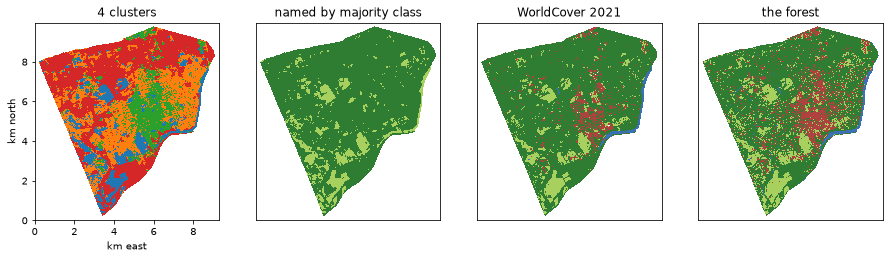

In [6]:
k = scene["choices"]["kmeans"]["k"]
assign, centres = fm.kmeans_map(q, valid, k)
named, mapping = fm.name_clusters(assign, labels10, k)
agree, rk = fm.agreement(named, cells["ref"], cells["y_ref"]), reference["kmeans"][str(k)]
print(f"k {k}: clusters named {sorted({fm.CLASS_NAMES[v] for v in mapping.values() if v})}; the named map "
      f"agrees with WorldCover on {agree:.1%} of the 319 reference cells   reference {rk['agreement']:.1%}, "
      f"the lecture's own run {rk['lecture']['agreement']:.1%}")
same = fm.partition_agreement(assign, cells[f"kmeans_{k}_lecture"], k)
print(f"your clusters agree with the lecture's on {same:.1%} of the cells once their numbers are matched")
fig = fm.show_maps([np.where(assign < 0, np.nan, assign), named, labels10, cells["map_forest"]],
                   [f"{k} clusters", "named by majority class", "WorldCover 2021", "the forest"],
                   ["tab10"] + [fm.class_cmap()] * 3, [0] * 4, [9, 4, 4, 4], extent)

k-means reads no label. It picks four centres, gives every cell to its nearest, moves each centre to the mean of its cells, and repeats, the toy's two rounds on half a million cells. The clusters are not classes: two of the four are tree cover, one is grass, and none is built-up or water, so the named map agrees with WorldCover by missing the rare classes. Your clusters differ from the lecture's on a few cells in a thousand, because the sums inside k-means follow their threads.

## A map from a handful of cells

The cell draws 25 labelled cells per class from the pool of Lecture 04, fits a logistic head on their 64 numbers, maps the town and scores the map.

100 labelled cells, 25 per class: agreement with WorldCover on the 319 reference cells 85.0%   reference 85.0%; the forest of Lecture 04 81.5 plus or minus 4.3, the majority class 78.7


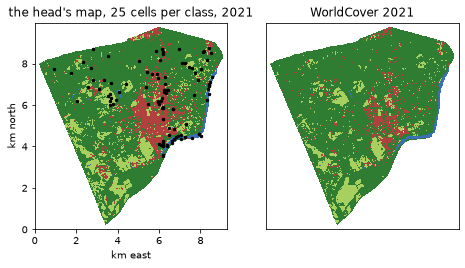

In [7]:
n = scene["choices"]["few_shot"]["per_class"]
drawn, y = fm.draw_cells(cells["pool"], cells["y_pool"], cells["pool_train"], n)
head = fm.few_shot_head(fm.cell_vectors(q, drawn), y)
map21 = fm.map_from_head(head, q, valid)
rf = reference["few_shot"]
on_ref = fm.agreement(map21, cells["ref"], cells["y_ref"])
print(f"{len(drawn)} labelled cells, {n} per class: agreement with WorldCover on the 319 reference cells "
      f"{on_ref:.1%}   reference {rf['reference']:.1%}; the forest of Lecture 04 {rf['forest']['reference']} "
      f"plus or minus {rf['forest']['interval']}, the majority class {rf['forest']['majority']}")
fig = fm.show_maps([map21, labels10], [f"the head's map, {n} cells per class, 2021", "WorldCover 2021"],
                   [fm.class_cmap()] * 2, [0] * 2, [4] * 2, extent)
fm.mark_cells(fig.axes[0], drawn, tr, q.shape[1:])

Lecture 04 trained a random forest on three thousand cells per class of eight hand-made numbers and reached 81.5 percent on the reference cells. A logistic head on 64 numbers it never chose, fitted on a hundred cells in all, the black dots, lands within the forest's interval, as the lecture's twenty draws did on average. Under four points is a tie on 319 cells, because three water cells make a step of 33 points. The dots were drawn outside the held-out blocks, for the next cell.

## Held out, and carried across years

The cell scores the same map on thousands of labelled cells in held-out blocks, then applies the 2021 head to the 2025 vectors and scores that map too.

on 60,000 held-out cells in other blocks 82.7%   reference 82.7%; the lecture's 20 draws averaged 79.3%
the same head on the 2025 vectors: reference cells 79.6%   reference 79.6%; held-out cells 78.3%


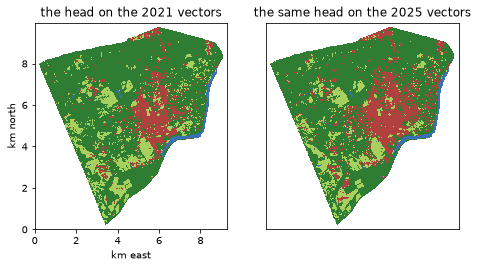

In [8]:
map25 = fm.map_from_head(head, e25["q"], e25["valid"])
on_ho, on_ref25 = fm.agreement(map21, ho, y_ho), fm.agreement(map25, cells["ref"], cells["y_ref"])
print(f"on {len(ho):,} held-out cells in other blocks {on_ho:.1%}   reference {rf['held_out']:.1%}; "
      f"the lecture's {rf['lecture']['draws']} draws averaged {rf['lecture']['held_out']:.1%}")
print(f"the same head on the 2025 vectors: reference cells {on_ref25:.1%}   reference "
      f"{rf['reference_2025']:.1%}; held-out cells {fm.agreement(map25, ho, y_ho):.1%}")
fig = fm.show_maps([map21, map25], ["the head on the 2021 vectors", "the same head on the 2025 vectors"],
                   [fm.class_cmap()] * 2, [0] * 2, [4] * 2, extent)

The reference cells are few, so the lecture scored every head a second time on 60,000 labelled cells drawn from the half of the town's blocks the labelled cells never came from. That score is lower, because the held-out cells include the mixed cells a reference sample avoids, and it is the one to trust. The 2025 map is the 2021 head carried across years without a new label, a few points lower again: a vintage is part of an embedding, and a poster states it.

## The lecture's curve

The cell draws the lecture's curve, labelled cells per class from 5 to 500 against the agreement on the reference cells and on the held-out cells.

labelled cells per class, agreement on the reference cells (its spread), on the held-out cells: 5: 0.795 (0.690 to 0.882), 0.750; 10: 0.813 (0.739 to 0.878), 0.770; 25: 0.827 (0.766 to 0.858), 0.793; 100: 0.843 (0.820 to 0.869), 0.813; 500: 0.857 (0.848 to 0.865), 0.833


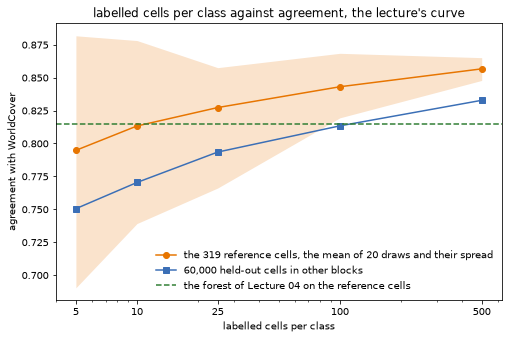

In [9]:
curve = reference["few_shot"]["curve"]
ns = sorted(int(k) for k in curve)
print("labelled cells per class, agreement on the reference cells (its spread), on the held-out cells: "
      + "; ".join(f"{k}: {curve[str(k)]['reference']:.3f} ({curve[str(k)]['low']:.3f} to "
                  f"{curve[str(k)]['high']:.3f}), {curve[str(k)]['held_out']:.3f}" for k in ns))
fig, ax = plt.subplots(figsize=(8, 5))
fm.show_curve(ax, curve, rf["forest"]["reference"] / 100,
              "labelled cells per class against agreement, the lecture's curve")

The curve answers the question Lecture 04 could not: how few labels are enough. Five per class already reach four fifths, 25 per class reach the forest, and 500 per class add two points more. The band is the spread of twenty draws, wide at five cells and narrow at five hundred, and the held-out line sits below the reference line throughout. A project with a hundred labelled places and a free embedding has a map, and its honest score is the lower line.

## Change since 2018

The cell reads the stability raster the lecture computed, the cosine of each cell's 2018 and 2025 vectors, counts the cells that changed, and repeats it for 2021 and 2025.

2018 to 2025: 3,420 of 476,595 cells below 0.6, 0.72%; Poe Field's cells 0.90   reference 3,420, 0.72%, 0.9037
2021 to 2025, computed here: 1.02% of the cells below 0.6   reference 1.02%


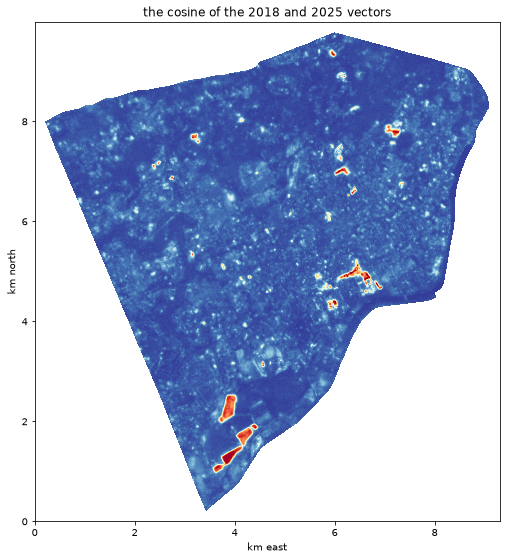

In [10]:
stab = fm.stability_to_cosine(fm.read_raster("data/stability_2018_2025.tif")[0])
t_change, pf, rc = scene["embeddings"]["change_threshold"], scene["poe_field"], reference["change"]
inside = stab[np.isfinite(stab)]
live = fm.change_score(q, e25["q"], valid)
poe = stab[pf["rows"][0]:pf["rows"][1], pf["cols"][0]:pf["cols"][1]]
print(f"2018 to 2025: {int((inside < t_change).sum()):,} of {len(inside):,} cells below {t_change}, "
      f"{(inside < t_change).mean():.2%}; Poe Field's cells {np.nanmean(poe):.2f}   reference "
      f"{rc['cells_below']:,}, {rc['share_below']:.2%}, {rc['poe_field']['mean']}")
print(f"2021 to 2025, computed here: {(live[valid] < t_change).mean():.2%} of the cells below {t_change}"
      f"   reference {rc['live_2021_vs_2025']['share_below']:.2%}")
fig, ax = plt.subplots(figsize=(9, 9))
fm.show_map(ax, stab, extent, "the cosine of the 2018 and 2025 vectors", cmap="RdYlBu", vmin=0.4, vmax=1)

Change is the cosine of a place with itself in another year. Most of the town scores above 0.9, and less than one cell in a hundred falls below 0.6: the new colleges south of Lake Carnegie, the warehouses along the highway, a solar field. Poe Field, where the class flew, is stable. The caveat of Lecture 04 holds: a different year is a different set of pictures, and a dry summer moves a lawn's vector too, so the lowest cells are a list to visit, not a map.

## Your turn

The head got 25 labelled cells per class. Give it 100 per class, the lecture's next step on the curve, and score the map again on the reference cells and on the held-out cells. Run the cell as it is, then change the marked value and run it again.

Did four times the labels buy four times the agreement, and which of the two scores moved more? What does the curve above say you should expect? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

In [11]:
PER_CLASS = 25  # change me: 100
drawn2, y2 = fm.draw_cells(cells["pool"], cells["y_pool"], cells["pool_train"], PER_CLASS)
head2 = fm.few_shot_head(fm.cell_vectors(q, drawn2), y2)
map2 = fm.map_from_head(head2, q, valid)
on_ref2, on_ho2 = fm.agreement(map2, cells["ref"], cells["y_ref"]), fm.agreement(map2, ho, y_ho)
print(f"{len(drawn2)} labelled cells: reference cells {on_ref2:.1%}, held-out cells {on_ho2:.1%}")

100 labelled cells: reference cells 85.0%, held-out cells 82.7%


## Check your understanding

1. The 64 numbers of a cell cannot be read one by one. What can be read from them, and what does the dataset's vintage change about it?
2. The clusters named by their majority class missed built-up and water. Why does the overall agreement still look high, and which number from Lecture 04 exposes it?
3. A head on 100 labelled cells ties a forest on 12,000. What did the embedding model learn in place of the labels, and from what?
4. A cell's cosine between 2018 and 2025 is 0.5. Name two reasons that are not construction.

## Where we are

You have read a planetary model's vector for every cell of the town, searched from a click, clustered without a label, mapped from a hundred labelled cells and scored the map as the lecture did, read the curve of labels against agreement, and measured change between years. You now know what an embedding is, what the three operations on it buy, and what a poster states about an embedding's vintage, its labels and its split. That closes the kit. Lecture 07 turns to the town's networks and the people who move on them.

## Further resources

Nothing in this course requires anything below.

- GeoAI with Python, chapter 16 on satellite embeddings, Qiusheng Wu, 2026, https://geoai.gishub.org
- AlphaEarth Foundations, Christopher Brown and colleagues, 2025, https://arxiv.org/abs/2507.22291
- TESSERA: temporal embeddings of surface spectra for Earth representation and analysis, Zhengpeng Feng and colleagues, 2025, https://arxiv.org/abs/2506.20380
- The open mirror of the AlphaEarth embeddings on Source Cooperative, https://source.coop/tge-labs/aef

The masks, numbers and this kit are the course's own work, published under CC BY 4.0. The imagery is NAIP 2023 of the USDA, public domain, read from the Planetary Computer. SAM 2.1 (Meta) is released under the Apache 2.0 licence, CLIP ViT-B/16 (OpenAI) under the MIT licence. The AlphaEarth Foundations Satellite Embedding dataset is produced by Google and Google DeepMind, licensed CC BY 4.0; the labels are ESA WorldCover 2021, CC BY 4.0.